1.Libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Student Dataset

In [ ]:
student_df = pd.read_csv("/content/drive/MyDrive/DATA SCIENCS/synthetic_student_performance_hidden.csv")
student_df.head()

,StudentID,Age,Gender,Subject,HoursStudied,StudyMethod,AttendanceRate,PreviousGrade,FinalExamScore,Passed
0,Student_0001,18.0,Male,Science,18.6,Tutoring,60.6,NaN,82.0,Yes
1,Student_0002,17.0,Male,English,4.1,Solo Study,NaN,NaN,66.0,Yes
2,Student_0003,18.0,Female,History,NaN,Solo Study,91.6,94.0,100.0,NaN
3,Student_0004,18.0,Female,Math,2.9,NaN,93.5,71.0,64.0,NaN
4,Student_0005,18.0,Female,English,1.6,Tutoring,91.3,NaN,61.0,NaN


# Data understanding

In [ ]:
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   StudentID       200 non-null    object 
 1   Age             166 non-null    float64
 2   Gender          163 non-null    object 
 3   Subject         162 non-null    object 
 4   HoursStudied    161 non-null    float64
 5   StudyMethod     167 non-null    object 
 6   AttendanceRate  166 non-null    float64
 7   PreviousGrade   164 non-null    float64
 8   FinalExamScore  175 non-null    float64
 9   Passed          146 non-null    object 
dtypes: float64(5), object(5)
memory usage: 15.8+ KB


In [ ]:
student_df.describe()

,Age,HoursStudied,AttendanceRate,PreviousGrade,FinalExamScore
count,166.000000,161.000000,166.000000,164.000000,175.000000
mean,16.114458,9.967081,79.550000,76.676829,74.588571
std,1.350253,5.794445,11.582007,14.030176,13.754075
min,14.000000,1.000000,60.600000,50.000000,39.000000
25%,15.000000,4.100000,69.550000,66.750000,63.000000
50%,16.000000,10.000000,79.100000,76.000000,75.000000
75%,17.000000,14.800000,89.900000,88.000000,84.500000
max,18.000000,19.700000,99.600000,100.000000,100.000000


# know Missing Values

In [ ]:
print("Missing Values Before Cleaning:")
student_df.isnull().sum()

Missing Values Before Cleaning:


,0
StudentID,0
Age,34
Gender,37
Subject,38
HoursStudied,39
StudyMethod,33
AttendanceRate,34
PreviousGrade,36
FinalExamScore,25
Passed,54


# Data cleaning

# Numerical

In [ ]:
student_df.fillna(student_df.mean(numeric_only=True), inplace=True)

# Categorical

In [ ]:
for col in student_df.select_dtypes(include='object'):
    student_df[col].fillna(student_df[col].mode()[0], inplace=True)

/tmp/ipykernel_851/558275939.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  student_df[col].fillna(student_df[col].mode()[0], inplace=True)


In [ ]:
print("Missing Values After Cleaning:")
print(student_df.isnull().sum())

Missing Values After Cleaning:
StudentID         0
Age               0
Gender            0
Subject           0
HoursStudied      0
StudyMethod       0
AttendanceRate    0
PreviousGrade     0
FinalExamScore    0
Passed            0
dtype: int64


# Duplicated values

In [ ]:
print("Before Removing Duplicates:", student_df.shape)

student_df.drop_duplicates(inplace=True)

print("After Removing Duplicates:", student_df.shape)

Before Removing Duplicates: (200, 10)
After Removing Duplicates: (200, 10)


#Boxplot Before

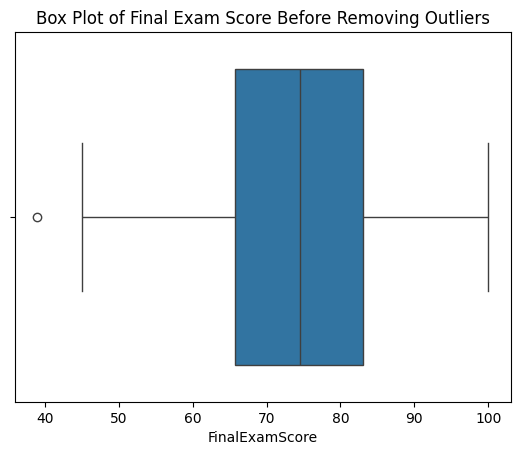

In [ ]:
sns.boxplot(x=student_df['FinalExamScore'])

plt.title('Box Plot of Final Exam Score Before Removing Outliers')

plt.show()

# Remove Outliers using IQR

In [ ]:

Q1 = student_df['FinalExamScore'].quantile(0.25)

Q3 = student_df['FinalExamScore'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

student_df = student_df[
    (student_df['FinalExamScore'] >= lower_bound) &
    (student_df['FinalExamScore'] <= upper_bound)
]

# Boxplot After

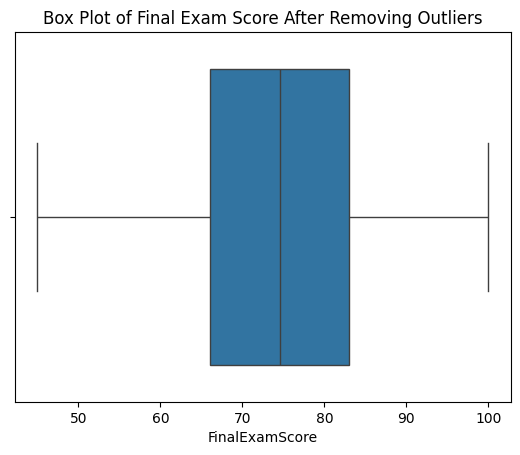

In [ ]:
sns.boxplot(x=student_df['FinalExamScore'])

plt.title('Box Plot of Final Exam Score After Removing Outliers')

plt.show()

# Encoding part

In [ ]:
le = LabelEncoder()

for col in student_df.select_dtypes(include='object'):
    student_df[col] = le.fit_transform(student_df[col])

# EDA

# Histogram

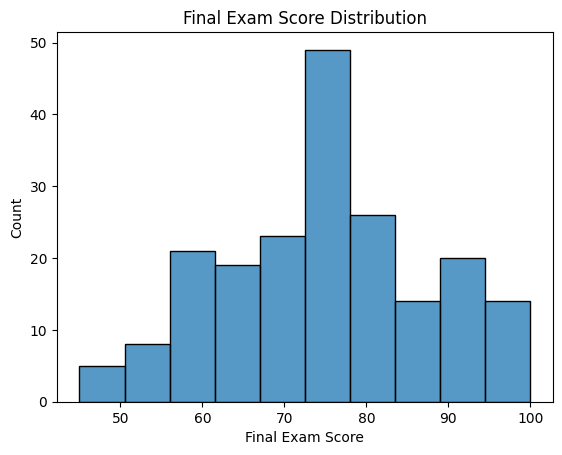

In [ ]:
sns.histplot(student_df['FinalExamScore'])

plt.title('Final Exam Score Distribution')

plt.xlabel('Final Exam Score')

plt.ylabel('Count')

plt.show()

Scatter Plot

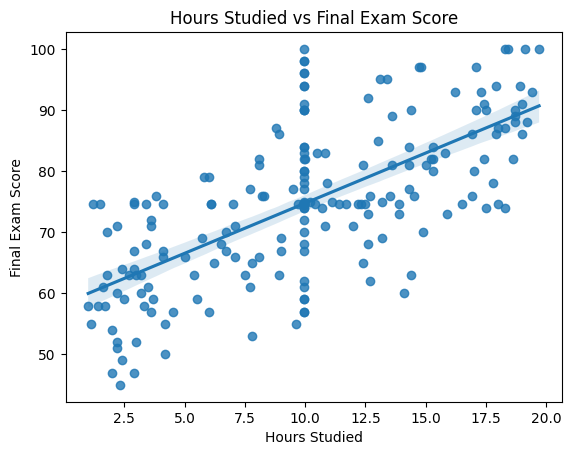

In [ ]:

sns.regplot(
    x=student_df['HoursStudied'],
    y=student_df['FinalExamScore']
)

plt.title('Hours Studied vs Final Exam Score')

plt.xlabel('Hours Studied')

plt.ylabel('Final Exam Score')

plt.show()


Heatmap

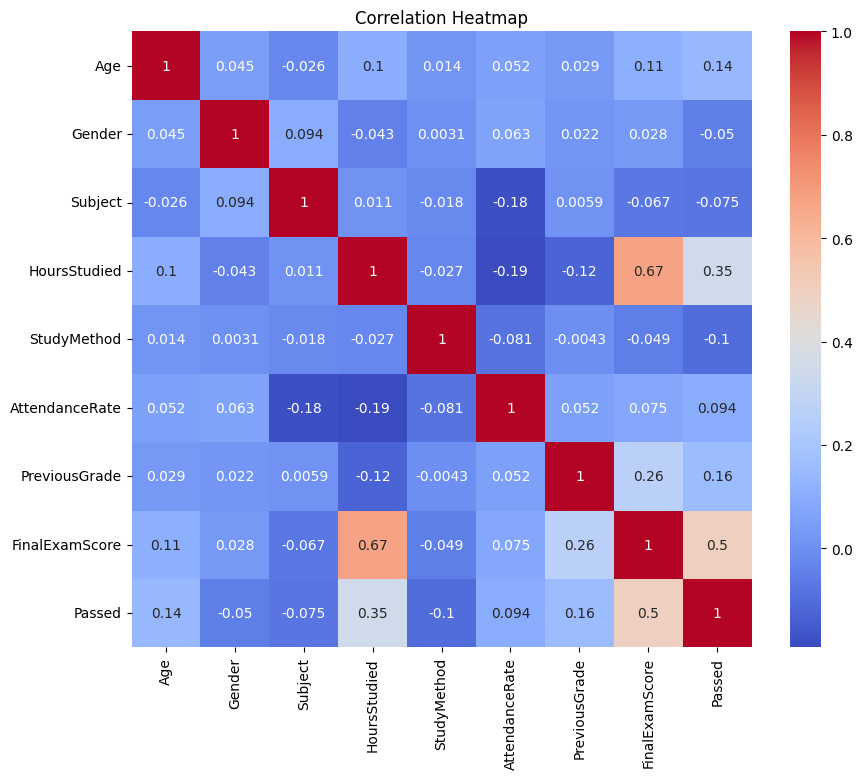

In [ ]:
student_df = student_df.drop('StudentID', axis=1)
plt.figure(figsize=(10,8))
sns.heatmap(student_df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

Target

In [ ]:

X = student_df[
    [
        'HoursStudied',
      'PreviousGrade',
    ]
]

y = student_df['FinalExamScore']


Data Spliting

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Scaling

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

# Polynomial

In [ ]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)

X_test_poly = poly.transform(X_test)

Linear Regression

In [ ]:

X = student_df[
    [
        'HoursStudied',
        'PreviousGrade',
    ]
]

y = student_df['FinalExamScore']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

lr = LinearRegression()

lr.fit(X_train_poly, y_train)
y_pred = lr.predict(X_test_poly)

# Prevent invalid predictions
y_pred = np.clip(y_pred, 0, 100)

r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

print(y_pred)


R2 Score: 0.6032965992593229
[88.83302683 64.58465698 71.91489682 92.42683429 69.43622881 80.81737162
 56.20892744 77.17624613 72.06487357 73.99417455 84.94373933 60.63915769
 86.07364161 83.07480904 76.93863625 77.36240845 74.52791356 62.505148
 86.25815945 62.46076893]


Model Rating

In [ ]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MSE:", mse)
print("RMSE:", rmse)

MSE: 65.05155267111732
RMSE: 8.06545427555803


Ridge Regression

In [ ]:
ridge = Ridge(alpha=10)

ridge.fit(X_train_poly, y_train)

ridge_pred = ridge.predict(X_test_poly)

ridge_pred = np.clip(ridge_pred, 0, 100)

ridge_mse = mean_squared_error(y_test, ridge_pred)

ridge_rmse = np.sqrt(ridge_mse)

ridge_r2 = r2_score(y_test, ridge_pred)
print("R2 Score:", ridge_r2)

R2 Score: 0.6013924286945005


Lasso Regression

In [ ]:
lasso = Lasso(alpha=0.1)

lasso.fit(X_train_poly, y_train)

lasso_pred = lasso.predict(X_test_poly)

lasso_pred = np.clip(lasso_pred, 0, 100)

lasso_mse = mean_squared_error(y_test, lasso_pred)

lasso_rmse = np.sqrt(lasso_mse)

lasso_r2 = r2_score(y_test, lasso_pred)
print("R2 Score:", lasso_r2 )

R2 Score: 0.6016253633618851


COMPARISONN

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge', 'Lasso'],
    'R2 Score': [r2, ridge_r2, lasso_r2],
    'MSE': [mse, ridge_mse, lasso_mse],
    'RMSE': [rmse, ridge_rmse, lasso_rmse]
})

print(comparison)

               Model  R2 Score        MSE      RMSE
0  Linear Regression  0.603297  65.051553  8.065454
1              Ridge  0.601392  65.363799  8.084788
2              Lasso  0.601625  65.325602  8.082426
